In [1]:

import os, sys, time
print("=== FRESHCHECK VEG 12% — VEGNET QUALITY CLASSIFICATION BOOT ===", flush=True)
print("[BOOT] Python:", sys.version, flush=True)
print("[BOOT] cwd:", os.getcwd(), flush=True)
print("[BOOT] heartbeat 1", flush=True); time.sleep(1)
print("[BOOT] heartbeat 2", flush=True)
open("/kaggle/working/FRESHCHECK_VEG_12PCT_STARTED.txt","w").write("started\n")
print("=== HEARTBEAT OK ===", flush=True)


=== FRESHCHECK VEG 12% — VEGNET QUALITY CLASSIFICATION BOOT ===
[BOOT] Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[BOOT] cwd: /kaggle/working
[BOOT] heartbeat 1
[BOOT] heartbeat 2
=== HEARTBEAT OK ===



# 12% — FreshCheck Veg
## Vegetable Quality Classification with EfficientNet-B0

> **Roadmap correction:** the original portfolio row was named **FreshCheck Fruit**, but the actual dataset is **VegNet**, which contains Bell Pepper, Chile Pepper, New Mexico Green Chile, and Tomato.  
> Therefore this notebook uses the technically correct framing: **FreshCheck Veg / produce-quality classification**.

### Validated task

Given one VegNet image, classify its **visual quality class** into:

1. Damaged
2. Dried
3. Old
4. Ripe
5. Unripe

The model **does not** predict:
- food safety;
- chemical freshness;
- internal quality;
- remaining shelf life;
- edibility;
- disease diagnosis;
- quality for arbitrary fruits/vegetables outside the dataset domain.

### Dataset sources

Hugging Face conversion used here:

- `Project-AgML/VegNet_quality_classification`
- https://huggingface.co/datasets/Project-AgML/VegNet_quality_classification

Original VegNet publication/data:

- Suryawanshi, Patil, Chumchu (2022), *VegNet: Dataset of vegetable quality images for machine learning applications*
- DOI: https://doi.org/10.1016/j.dib.2022.108657
- Mendeley Data: https://data.mendeley.com/datasets/6nxnjbn9w6/1
- License: CC BY 4.0

The original paper describes **6,850 images**, while the Hugging Face quality-classification conversion mounted here contains **6,150 rows**. This notebook treats the mounted Parquet file as the experiment source of truth and explicitly audits the difference.


In [2]:

import importlib.util, subprocess, sys

required = {
    "pyarrow": "pyarrow",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "PIL": "Pillow",
}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]

if missing:
    print("[SETUP] Installing:", missing, flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

print("[SETUP] base dependencies OK")


[SETUP] base dependencies OK


In [3]:

from pathlib import Path
from io import BytesIO
from collections import Counter
import hashlib, json, random, shutil, math, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

DATA_DIR = Path("/kaggle/input/datasets/loliwibu/vegnet/data")
PARQUET = DATA_DIR / "train-00000-of-00001.parquet"

WORK = Path("/kaggle/working/freshcheck_veg_12pct")
REPORT_DIR = WORK / "reports"
ASSET_DIR = WORK / "assets"
MODEL_DIR = WORK / "models"

for p in [WORK, REPORT_DIR, ASSET_DIR, MODEL_DIR]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LABEL_NAMES = {
    0: "Damaged",
    1: "Dried",
    2: "Old",
    3: "Ripe",
    4: "Unripe",
}

CROP_NAMES = {
    0: "Bell Pepper",
    1: "Chile Pepper",
    2: "New Mexico Green Chile",
    3: "Tomato",
}

print("[CONFIG] parquet:", PARQUET)
print("[CONFIG] exists:", PARQUET.exists())
print("[CONFIG] device:", DEVICE)
if torch.cuda.is_available():
    print("[CONFIG] GPU:", torch.cuda.get_device_name(0))

assert PARQUET.exists(), f"Parquet not found: {PARQUET}"


[CONFIG] parquet: /kaggle/input/datasets/loliwibu/vegnet/data/train-00000-of-00001.parquet
[CONFIG] exists: True
[CONFIG] device: cuda
[CONFIG] GPU: Tesla T4



## 1. Load the mounted Parquet — audit before training

The Hugging Face conversion stores each JPEG directly inside the Parquet `image` field.

Expected columns:

```text
image
label
crop_type
```

Expected label mapping from the Hugging Face dataset schema:

```text
0 Damaged
1 Dried
2 Old
3 Ripe
4 Unripe
```

Expected crop mapping:

```text
0 Bell Pepper
1 Chile Pepper
2 New Mexico Green Chile
3 Tomato
```


In [4]:

df = pd.read_parquet(PARQUET)

print("[DATA] shape:", df.shape)
print("[DATA] columns:", df.columns.tolist())
display(df.head())

required_cols = {"image", "label", "crop_type"}
assert required_cols.issubset(df.columns), f"Missing required columns: {required_cols - set(df.columns)}"

print("\n[DATA] dtypes:")
print(df.dtypes)


[DATA] shape: (6150, 3)
[DATA] columns: ['image', 'label', 'crop_type']


,image,label,crop_type
0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,0,0
1,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,0,0
2,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,0,0
3,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,0,0
4,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,0,0



[DATA] dtypes:
image        object
label         int64
crop_type     int64
dtype: object


## 2. Verify mappings, class counts, crop counts, and crop × quality coverage

=== QUALITY DISTRIBUTION ===
0    Damaged:  317
1      Dried: 1389
2        Old: 2044
3       Ripe: 1787
4     Unripe:  613

=== CROP DISTRIBUTION ===
0             Bell Pepper: 1176
1            Chile Pepper: 1286
2  New Mexico Green Chile: 1327
3                  Tomato: 2361

=== CROP × QUALITY ===


label_name,Damaged,Dried,Old,Ripe,Unripe
crop_name,,,,,
Bell Pepper,31,296,349,448,52
Chile Pepper,121,593,200,183,189
New Mexico Green Chile,138,500,261,201,227
Tomato,27,0,1234,955,145


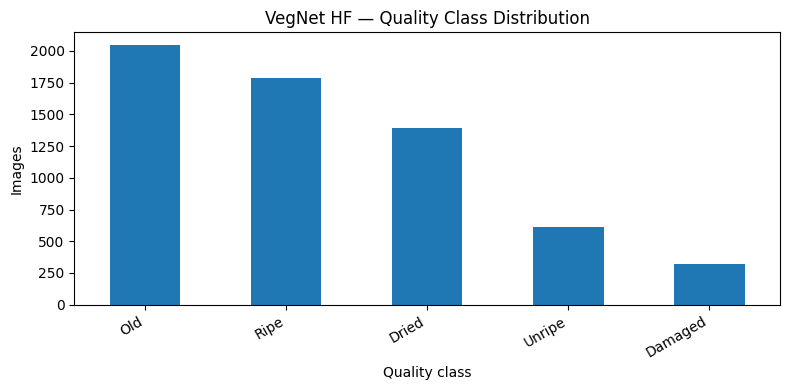

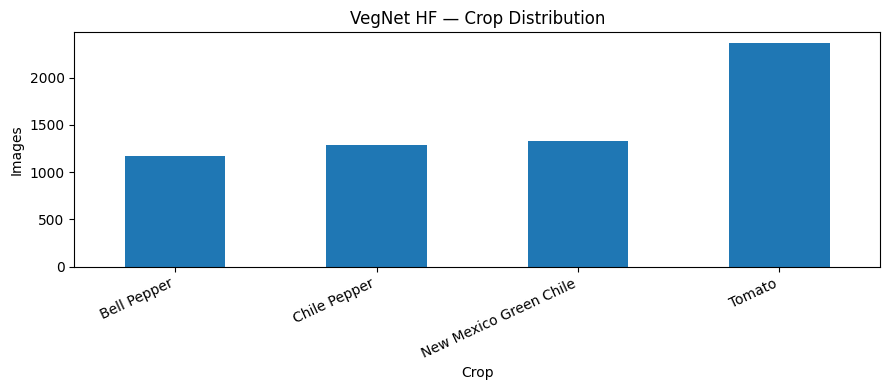

In [5]:

df["label_name"] = df["label"].map(LABEL_NAMES)
df["crop_name"] = df["crop_type"].map(CROP_NAMES)

assert df["label_name"].notna().all(), "Unknown label id found."
assert df["crop_name"].notna().all(), "Unknown crop_type id found."

label_counts = df["label"].value_counts().sort_index()
crop_counts = df["crop_type"].value_counts().sort_index()

print("=== QUALITY DISTRIBUTION ===")
for k, v in label_counts.items():
    print(f"{k} {LABEL_NAMES[k]:>10}: {v:>4}")

print("\n=== CROP DISTRIBUTION ===")
for k, v in crop_counts.items():
    print(f"{k} {CROP_NAMES[k]:>23}: {v:>4}")

cross = pd.crosstab(df["crop_name"], df["label_name"])
cross = cross.reindex(index=list(CROP_NAMES.values()), columns=list(LABEL_NAMES.values()), fill_value=0)

print("\n=== CROP × QUALITY ===")
display(cross)

label_counts_named = pd.Series(
    {LABEL_NAMES[k]: int(v) for k, v in label_counts.items()}
).sort_values(ascending=False)

fig = plt.figure(figsize=(8, 4))
label_counts_named.plot(kind="bar")
plt.title("VegNet HF — Quality Class Distribution")
plt.ylabel("Images")
plt.xlabel("Quality class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(ASSET_DIR / "quality_class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

fig = plt.figure(figsize=(9, 4))
crop_counts_named = pd.Series({CROP_NAMES[k]: int(v) for k, v in crop_counts.items()})
crop_counts_named.plot(kind="bar")
plt.title("VegNet HF — Crop Distribution")
plt.ylabel("Images")
plt.xlabel("Crop")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(ASSET_DIR / "crop_distribution.png", dpi=160, bbox_inches="tight")
plt.show()



## 3. Dataset-specific finding: this is not the full original 6,850-image VegNet

The original Data in Brief paper reports:

```text
Damaged : 317
Dried   : 1389
Old     : 2044
Ripe    : 1787
Unripe  : 1313
Total   : 6850
```

The mounted Hugging Face conversion contains:

```text
Damaged : 317
Dried   : 1389
Old     : 2044
Ripe    : 1787
Unripe  : 613
Total   : 6150
```

The difference is exactly **700 images**, all within the original Unripe total.

The original paper lists **845 Unripe Tomato** images, while the mounted conversion has **145**.  
This notebook does not try to reconstruct the missing 700 images; it trains only on what is actually mounted.


In [6]:

paper_expected = {
    "Damaged": 317,
    "Dried": 1389,
    "Old": 2044,
    "Ripe": 1787,
    "Unripe": 1313,
}

mounted_counts = {LABEL_NAMES[k]: int(v) for k, v in label_counts.items()}

comparison = pd.DataFrame({
    "original_paper": pd.Series(paper_expected),
    "mounted_hf": pd.Series(mounted_counts),
})
comparison["difference"] = comparison["mounted_hf"] - comparison["original_paper"]
display(comparison)

print("[AUDIT] original paper total:", sum(paper_expected.values()))
print("[AUDIT] mounted HF total:", len(df))
print("[AUDIT] total difference:", len(df) - sum(paper_expected.values()))

if len(df) == 6150 and mounted_counts.get("Unripe") == 613:
    print("[AUDIT] Mounted export matches the known 6,150-row HF conversion.")
else:
    print("[WARN] Mounted dataset differs from the expected HF conversion; use printed counts as source of truth.")


,original_paper,mounted_hf,difference
Damaged,317,317,0
Dried,1389,1389,0
Old,2044,2044,0
Ripe,1787,1787,0
Unripe,1313,613,-700


[AUDIT] original paper total: 6850
[AUDIT] mounted HF total: 6150
[AUDIT] total difference: -700
[AUDIT] Mounted export matches the known 6,150-row HF conversion.



## 4. Important dataset bias: crop type and quality are not independent

Quality classes are not uniformly represented across crops.

For example, the mounted data has:

- no `Dried` Tomato examples;
- relatively few `Damaged` Tomato examples;
- strongly different quality distributions across crop types.

This means a quality model can partially exploit crop identity as a shortcut.

Mitigation in this MVP:

1. `crop_type` is **not** fed as an explicit model input;
2. splitting is stratified by **crop × quality combination**;
3. final evaluation reports both overall metrics and **per-crop metrics**;
4. claims are limited to the four VegNet crops.


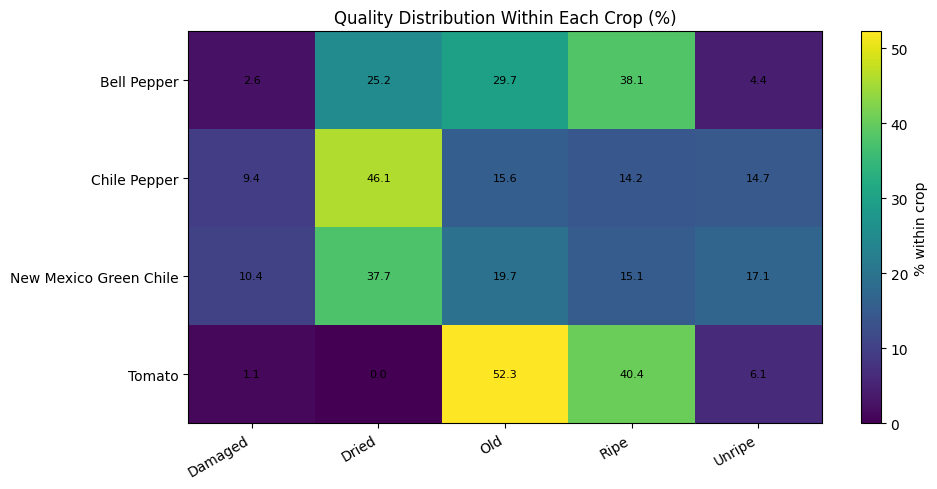

In [7]:

row_pct = cross.div(cross.sum(axis=1), axis=0) * 100

fig = plt.figure(figsize=(10, 5))
plt.imshow(row_pct.values, aspect="auto")
plt.colorbar(label="% within crop")
plt.xticks(range(len(row_pct.columns)), row_pct.columns, rotation=30, ha="right")
plt.yticks(range(len(row_pct.index)), row_pct.index)
plt.title("Quality Distribution Within Each Crop (%)")

for i in range(row_pct.shape[0]):
    for j in range(row_pct.shape[1]):
        plt.text(j, i, f"{row_pct.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(ASSET_DIR / "crop_quality_distribution_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Decode audit — verify image bytes, dimensions, and readability

In [8]:

def extract_bytes(value):
    if isinstance(value, dict):
        b = value.get("bytes")
        if b is not None:
            return b
        p = value.get("path")
        if p:
            return Path(p).read_bytes()
    if isinstance(value, (bytes, bytearray, memoryview)):
        return bytes(value)
    raise TypeError(f"Unsupported image field type: {type(value)}")

def decode_image(value):
    b = extract_bytes(value)
    with Image.open(BytesIO(b)) as im:
        return ImageOps.exif_transpose(im).convert("RGB")

decode_rows = []
bad_indices = []

for idx, value in enumerate(df["image"]):
    try:
        im = decode_image(value)
        decode_rows.append({
            "index": idx,
            "width": im.width,
            "height": im.height,
            "mode": im.mode,
        })
    except Exception as e:
        bad_indices.append((idx, repr(e)))

decode_df = pd.DataFrame(decode_rows)

print("[IMAGE AUDIT] readable:", len(decode_df))
print("[IMAGE AUDIT] unreadable:", len(bad_indices))
display(decode_df.groupby(["width", "height", "mode"]).size().rename("count").reset_index())

if bad_indices:
    display(pd.DataFrame(bad_indices, columns=["index", "error"]).head(20))


[IMAGE AUDIT] readable: 6150
[IMAGE AUDIT] unreadable: 0


,width,height,mode,count
0,256,256,RGB,6150


## 6. Visual audit — random examples by quality class

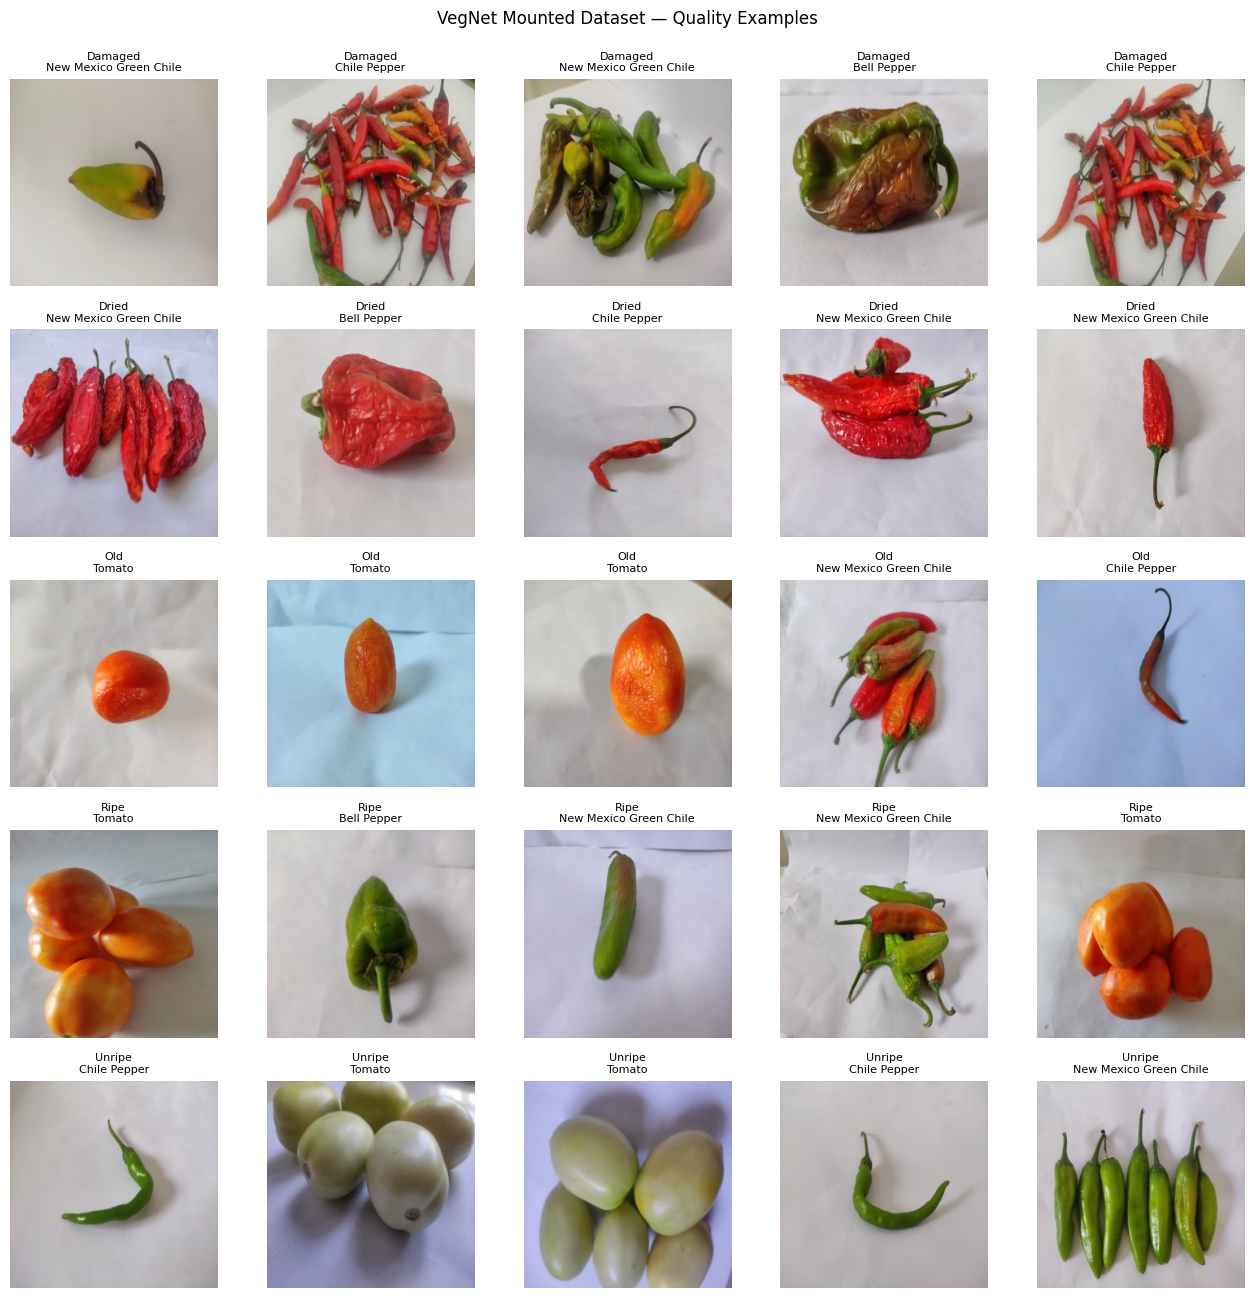

In [9]:

rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(5, 5, figsize=(13, 13))

for label_id in range(5):
    candidates = df.index[df["label"] == label_id].to_numpy()
    sample_ids = rng.choice(candidates, size=min(5, len(candidates)), replace=False)

    for col, idx in enumerate(sample_ids):
        im = decode_image(df.at[idx, "image"])
        ax = axes[label_id, col]
        ax.imshow(im)
        ax.set_title(
            f"{LABEL_NAMES[label_id]}\n{CROP_NAMES[int(df.at[idx, 'crop_type'])]}",
            fontsize=8,
        )
        ax.axis("off")

plt.suptitle("VegNet Mounted Dataset — Quality Examples", y=0.995)
plt.tight_layout()
plt.savefig(ASSET_DIR / "dataset_quality_examples.png", dpi=160, bbox_inches="tight")
plt.show()



## 7. Exact duplicate audit

The image bytes are hashed before splitting.

Policy:

- identical bytes with identical metadata → keep one copy;
- identical bytes with conflicting labels/crop metadata → exclude the whole conflicting hash group from model development;
- split only after this audit.

This prevents byte-identical copies from leaking across train/validation/test.


In [10]:

def md5_bytes(value):
    return hashlib.md5(extract_bytes(value)).hexdigest()

df["md5"] = [md5_bytes(v) for v in df["image"]]

hash_stats = (
    df.groupby("md5")
      .agg(
          rows=("md5", "size"),
          labels=("label", "nunique"),
          crops=("crop_type", "nunique"),
      )
)

duplicate_hashes = hash_stats[hash_stats["rows"] > 1]
conflicting_hashes = duplicate_hashes[
    (duplicate_hashes["labels"] > 1) | (duplicate_hashes["crops"] > 1)
]

print("[DUPLICATES] duplicate hash groups:", len(duplicate_hashes))
print("[DUPLICATES] duplicate rows beyond first:", int((duplicate_hashes["rows"] - 1).sum()))
print("[DUPLICATES] conflicting duplicate groups:", len(conflicting_hashes))

if len(conflicting_hashes):
    display(conflicting_hashes.head(20))

conflict_set = set(conflicting_hashes.index)

work_df = df[~df["md5"].isin(conflict_set)].copy()
before_dedup = len(work_df)
work_df = work_df.drop_duplicates(subset=["md5"], keep="first").reset_index(drop=True)

print("[CLEAN] rows before same-label exact dedup:", before_dedup)
print("[CLEAN] rows after exact dedup:", len(work_df))


[DUPLICATES] duplicate hash groups: 0
[DUPLICATES] duplicate rows beyond first: 0
[DUPLICATES] conflicting duplicate groups: 0
[CLEAN] rows before same-label exact dedup: 6150
[CLEAN] rows after exact dedup: 6150



## 8. Build a leakage-conscious internal split

The Hugging Face conversion provides only one official `train` split.

Therefore this notebook creates an **internal** split:

```text
70% train
15% validation
15% held-out test
```

Stratification uses:

```text
crop_type × quality_label
```

rather than quality label alone.

Why?

Because the dataset is strongly crop-dependent, and we want each available crop-quality combination represented proportionally across splits.

This internal held-out test is valid for this notebook experiment, but it is still derived from the same source dataset and should not be described as external validation.


In [11]:

work_df["strata"] = (
    work_df["crop_type"].astype(str) + "_" + work_df["label"].astype(str)
)

strata_counts = work_df["strata"].value_counts()
rare_strata = strata_counts[strata_counts < 3]

print("[SPLIT] number of crop-quality strata:", work_df["strata"].nunique())
print("[SPLIT] rare strata <3:", rare_strata.to_dict())

if len(rare_strata):
    warnings.warn(
        "Some crop-quality combinations have fewer than 3 samples. "
        "Falling back to label-only stratification."
    )
    split_key = work_df["label"].astype(str)
else:
    split_key = work_df["strata"]

train_df, temp_df = train_test_split(
    work_df,
    test_size=0.30,
    random_state=SEED,
    stratify=split_key,
)

temp_key = (
    temp_df["crop_type"].astype(str) + "_" + temp_df["label"].astype(str)
)

if (temp_key.value_counts() < 2).any():
    temp_key = temp_df["label"].astype(str)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_key,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("[SPLIT] train:", len(train_df))
print("[SPLIT] val  :", len(val_df))
print("[SPLIT] test :", len(test_df))

# Leakage check
train_hash = set(train_df["md5"])
val_hash = set(val_df["md5"])
test_hash = set(test_df["md5"])

assert not (train_hash & val_hash)
assert not (train_hash & test_hash)
assert not (val_hash & test_hash)

print("[SPLIT] exact-hash leakage: 0")

def split_table(frame, name):
    out = pd.crosstab(frame["crop_name"], frame["label_name"])
    out = out.reindex(index=list(CROP_NAMES.values()), columns=list(LABEL_NAMES.values()), fill_value=0)
    print(f"\n=== {name.upper()} CROP × QUALITY ===")
    display(out)

split_table(train_df, "train")
split_table(val_df, "val")
split_table(test_df, "test")


[SPLIT] number of crop-quality strata: 19
[SPLIT] rare strata <3: {}
[SPLIT] train: 4305
[SPLIT] val  : 922
[SPLIT] test : 923
[SPLIT] exact-hash leakage: 0

=== TRAIN CROP × QUALITY ===


label_name,Damaged,Dried,Old,Ripe,Unripe
crop_name,,,,,
Bell Pepper,22,207,244,314,36
Chile Pepper,85,415,140,128,132
New Mexico Green Chile,97,350,183,141,159
Tomato,19,0,864,668,101



=== VAL CROP × QUALITY ===


label_name,Damaged,Dried,Old,Ripe,Unripe
crop_name,,,,,
Bell Pepper,5,44,52,67,8
Chile Pepper,18,89,30,28,28
New Mexico Green Chile,21,75,39,30,34
Tomato,4,0,185,143,22



=== TEST CROP × QUALITY ===


label_name,Damaged,Dried,Old,Ripe,Unripe
crop_name,,,,,
Bell Pepper,4,45,53,67,8
Chile Pepper,18,89,30,27,29
New Mexico Green Chile,20,75,39,30,34
Tomato,4,0,185,144,22


In [12]:

split_manifest = pd.concat([
    train_df[["md5","label","label_name","crop_type","crop_name"]].assign(split="train"),
    val_df[["md5","label","label_name","crop_type","crop_name"]].assign(split="val"),
    test_df[["md5","label","label_name","crop_type","crop_name"]].assign(split="test"),
], ignore_index=True)

split_manifest.to_csv(REPORT_DIR / "split_manifest.csv", index=False)
print("[SAVED]", REPORT_DIR / "split_manifest.csv")


[SAVED] /kaggle/working/freshcheck_veg_12pct/reports/split_manifest.csv



## 9. Model strategy

### EfficientNet-B0

The portfolio roadmap proposed EfficientNet, so the final baseline uses **EfficientNet-B0** with ImageNet initialization.

Training is performed in two stages:

### Stage 1 — classifier warm-up

- freeze feature extractor;
- train classifier head only;
- establish a stable task-specific head.

### Stage 2 — fine-tuning

- unfreeze the network;
- lower learning rate;
- use class-weighted cross entropy;
- use label smoothing;
- early stopping by validation **Macro-F1**.

### Why Macro-F1?

The mounted dataset is imbalanced:

```text
Damaged  : 317
Dried    : 1389
Old      : 2044
Ripe     : 1787
Unripe   : 613
```

Accuracy alone could hide poor performance on `Damaged` or `Unripe`.


In [13]:

IMG_SIZE = 224

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.12,
        hue=0.03,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

class VegNetParquetDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = decode_image(row["image"])
        image = self.transform(image)

        return {
            "image": image,
            "label": torch.tensor(int(row["label"]), dtype=torch.long),
            "crop_type": torch.tensor(int(row["crop_type"]), dtype=torch.long),
            "md5": row["md5"],
        }

train_ds = VegNetParquetDataset(train_df, train_tfms)
val_ds = VegNetParquetDataset(val_df, eval_tfms)
test_ds = VegNetParquetDataset(test_df, eval_tfms)

BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

print("[LOADER] train batches:", len(train_loader))
print("[LOADER] val batches:", len(val_loader))
print("[LOADER] test batches:", len(test_loader))


[LOADER] train batches: 135
[LOADER] val batches: 29
[LOADER] test batches: 29


## 10. Class weights and naive baseline

In [14]:

train_counts = train_df["label"].value_counts().sort_index().reindex(range(5), fill_value=0).values.astype(float)

class_weights = len(train_df) / (len(train_counts) * train_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

print("[WEIGHTS]")
for i, w in enumerate(class_weights.detach().cpu().numpy()):
    print(f"{i} {LABEL_NAMES[i]:>10}: {w:.4f}")

majority_class = int(train_df["label"].value_counts().idxmax())
majority_pred = np.full(len(test_df), majority_class)
majority_acc = accuracy_score(test_df["label"], majority_pred)
majority_macro_f1 = f1_score(test_df["label"], majority_pred, average="macro", zero_division=0)

print("\n[NAIVE BASELINE]")
print("majority class:", LABEL_NAMES[majority_class])
print(f"test accuracy: {majority_acc:.4f}")
print(f"test macro-F1: {majority_macro_f1:.4f}")


[WEIGHTS]
0    Damaged: 3.8610
1      Dried: 0.8858
2        Old: 0.6017
3       Ripe: 0.6882
4     Unripe: 2.0117

[NAIVE BASELINE]
majority class: Old
test accuracy: 0.3326
test macro-F1: 0.0998


## 11. Build EfficientNet-B0

In [15]:

try:
    weights = EfficientNet_B0_Weights.DEFAULT
    model = efficientnet_b0(weights=weights)
    print("[MODEL] Loaded ImageNet pretrained EfficientNet-B0.")
except Exception as e:
    print("[WARN] Could not load pretrained weights:", repr(e))
    print("[WARN] Falling back to random initialization.")
    model = efficientnet_b0(weights=None)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 5)
model = model.to(DEVICE)

print(model.classifier)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s] 


[MODEL] Loaded ImageNet pretrained EfficientNet-B0.
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)


In [16]:

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05,
)

scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    ys = []
    preds = []
    crops = []

    for batch in loader:
        x = batch["image"].to(DEVICE, non_blocking=True)
        y = batch["label"].to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available(),
        ):
            logits = model(x)
            loss = criterion(logits, y)

        if training:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * x.size(0)
        p = logits.argmax(dim=1)

        ys.extend(y.detach().cpu().numpy().tolist())
        preds.extend(p.detach().cpu().numpy().tolist())
        crops.extend(batch["crop_type"].numpy().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(ys, preds)
    bal_acc = balanced_accuracy_score(ys, preds)
    macro_f1 = f1_score(ys, preds, average="macro", zero_division=0)

    return {
        "loss": avg_loss,
        "accuracy": acc,
        "balanced_accuracy": bal_acc,
        "macro_f1": macro_f1,
        "y_true": np.asarray(ys),
        "y_pred": np.asarray(preds),
        "crop_type": np.asarray(crops),
    }


## 12. Stage 1 — train classifier head only

In [17]:

for p in model.features.parameters():
    p.requires_grad = False

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3,
    weight_decay=1e-4,
)

STAGE1_EPOCHS = 3
history = []

for epoch in range(1, STAGE1_EPOCHS + 1):
    tr = run_epoch(model, train_loader, optimizer)
    va = run_epoch(model, val_loader)

    history.append({
        "stage": "head",
        "epoch": epoch,
        "train_loss": tr["loss"],
        "train_accuracy": tr["accuracy"],
        "train_macro_f1": tr["macro_f1"],
        "val_loss": va["loss"],
        "val_accuracy": va["accuracy"],
        "val_balanced_accuracy": va["balanced_accuracy"],
        "val_macro_f1": va["macro_f1"],
    })

    print(
        f"[HEAD {epoch:02d}/{STAGE1_EPOCHS}] "
        f"train_loss={tr['loss']:.4f} "
        f"train_f1={tr['macro_f1']:.4f} | "
        f"val_loss={va['loss']:.4f} "
        f"val_acc={va['accuracy']:.4f} "
        f"val_macro_f1={va['macro_f1']:.4f}",
        flush=True,
    )


[HEAD 01/3] train_loss=1.0568 train_f1=0.6130 | val_loss=0.7603 val_acc=0.7983 val_macro_f1=0.7773
[HEAD 02/3] train_loss=0.7842 train_f1=0.7578 | val_loss=0.6857 val_acc=0.8189 val_macro_f1=0.7973
[HEAD 03/3] train_loss=0.7296 train_f1=0.7855 | val_loss=0.6449 val_acc=0.8330 val_macro_f1=0.8162


## 13. Stage 2 — full fine-tuning with early stopping

In [18]:

for p in model.features.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1.5e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

MAX_EPOCHS = 20
PATIENCE = 5

best_f1 = -1.0
best_epoch = None
wait = 0

best_path = MODEL_DIR / "freshcheck_effnet_b0_best.pt"

for epoch in range(1, MAX_EPOCHS + 1):
    tr = run_epoch(model, train_loader, optimizer)
    va = run_epoch(model, val_loader)

    scheduler.step(va["macro_f1"])
    lr = optimizer.param_groups[0]["lr"]

    history.append({
        "stage": "finetune",
        "epoch": epoch,
        "lr": lr,
        "train_loss": tr["loss"],
        "train_accuracy": tr["accuracy"],
        "train_macro_f1": tr["macro_f1"],
        "val_loss": va["loss"],
        "val_accuracy": va["accuracy"],
        "val_balanced_accuracy": va["balanced_accuracy"],
        "val_macro_f1": va["macro_f1"],
    })

    print(
        f"[FT {epoch:02d}/{MAX_EPOCHS}] "
        f"lr={lr:.2e} "
        f"train_loss={tr['loss']:.4f} "
        f"train_f1={tr['macro_f1']:.4f} | "
        f"val_loss={va['loss']:.4f} "
        f"val_acc={va['accuracy']:.4f} "
        f"val_bal_acc={va['balanced_accuracy']:.4f} "
        f"val_macro_f1={va['macro_f1']:.4f}",
        flush=True,
    )

    if va["macro_f1"] > best_f1 + 1e-5:
        best_f1 = va["macro_f1"]
        best_epoch = epoch
        wait = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "label_names": LABEL_NAMES,
            "crop_names": CROP_NAMES,
            "img_size": IMG_SIZE,
            "best_val_macro_f1": best_f1,
            "best_epoch": best_epoch,
            "seed": SEED,
        }, best_path)

        print("[BEST] saved:", best_path)
    else:
        wait += 1

    if wait >= PATIENCE:
        print(f"[EARLY STOP] no Macro-F1 improvement for {PATIENCE} epochs")
        break

print("[TRAIN] best val Macro-F1:", best_f1)
print("[TRAIN] best fine-tune epoch:", best_epoch)


[FT 01/20] lr=1.50e-04 train_loss=0.5982 train_f1=0.8665 | val_loss=0.4973 val_acc=0.9035 val_bal_acc=0.9339 val_macro_f1=0.8809
[BEST] saved: /kaggle/working/freshcheck_veg_12pct/models/freshcheck_effnet_b0_best.pt
[FT 02/20] lr=1.50e-04 train_loss=0.4706 train_f1=0.9436 | val_loss=0.4423 val_acc=0.9577 val_bal_acc=0.9628 val_macro_f1=0.9493
[BEST] saved: /kaggle/working/freshcheck_veg_12pct/models/freshcheck_effnet_b0_best.pt
[FT 03/20] lr=1.50e-04 train_loss=0.4283 train_f1=0.9645 | val_loss=0.4107 val_acc=0.9772 val_bal_acc=0.9805 val_macro_f1=0.9670
[BEST] saved: /kaggle/working/freshcheck_veg_12pct/models/freshcheck_effnet_b0_best.pt
[FT 04/20] lr=1.50e-04 train_loss=0.4089 train_f1=0.9765 | val_loss=0.4143 val_acc=0.9751 val_bal_acc=0.9736 val_macro_f1=0.9711
[BEST] saved: /kaggle/working/freshcheck_veg_12pct/models/freshcheck_effnet_b0_best.pt
[FT 05/20] lr=1.50e-04 train_loss=0.3960 train_f1=0.9794 | val_loss=0.3947 val_acc=0.9816 val_bal_acc=0.9784 val_macro_f1=0.9788
[BEST] 

## 14. Training curves

,stage,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_balanced_accuracy,val_macro_f1,lr
11,finetune,9,0.361670,0.993728,0.993013,0.371902,0.990239,0.985386,0.985229,0.000150
12,finetune,10,0.359836,0.996051,0.995643,0.370819,0.991323,0.986039,0.986039,0.000150
13,finetune,11,0.360086,0.995354,0.995134,0.383775,0.988069,0.983801,0.982455,0.000075
14,finetune,12,0.351600,0.996748,0.996417,0.374671,0.990239,0.985293,0.984593,0.000075
15,finetune,13,0.353183,0.996748,0.996381,0.367434,0.992408,0.990113,0.987766,0.000075


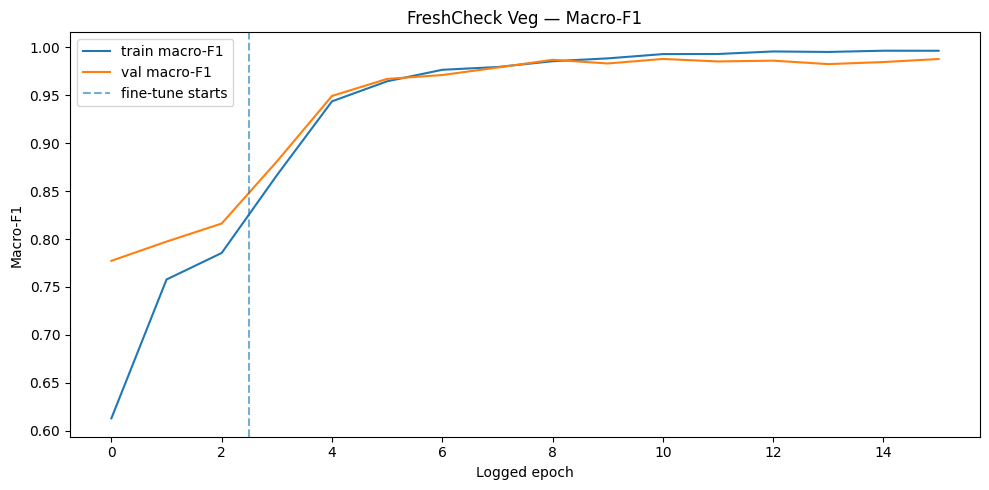

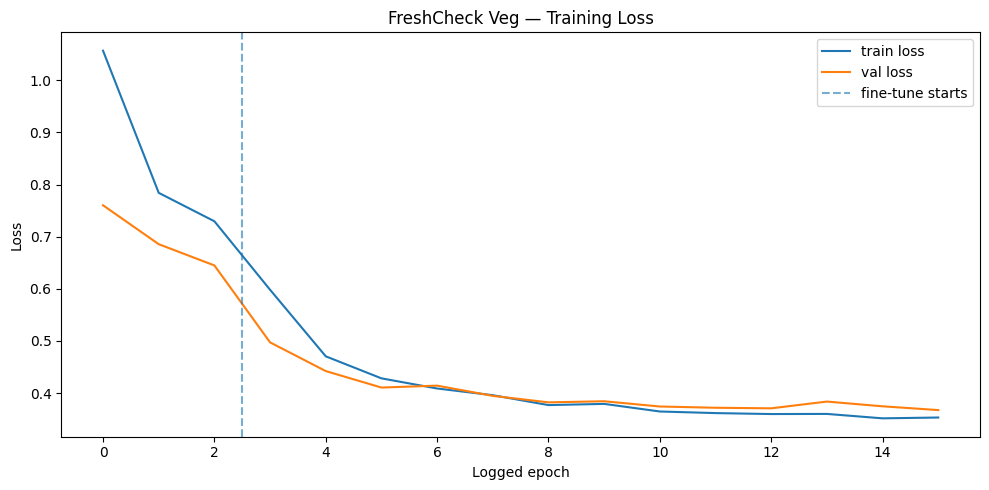

In [19]:

history_df = pd.DataFrame(history)
history_df.to_csv(REPORT_DIR / "training_history.csv", index=False)

display(history_df.tail())

fig = plt.figure(figsize=(10, 5))
x = np.arange(len(history_df))
plt.plot(x, history_df["train_macro_f1"], label="train macro-F1")
plt.plot(x, history_df["val_macro_f1"], label="val macro-F1")
plt.axvline(STAGE1_EPOCHS - 0.5, linestyle="--", alpha=0.6, label="fine-tune starts")
plt.xlabel("Logged epoch")
plt.ylabel("Macro-F1")
plt.title("FreshCheck Veg — Macro-F1")
plt.legend()
plt.tight_layout()
plt.savefig(ASSET_DIR / "training_macro_f1.png", dpi=160, bbox_inches="tight")
plt.show()

fig = plt.figure(figsize=(10, 5))
plt.plot(x, history_df["train_loss"], label="train loss")
plt.plot(x, history_df["val_loss"], label="val loss")
plt.axvline(STAGE1_EPOCHS - 0.5, linestyle="--", alpha=0.6, label="fine-tune starts")
plt.xlabel("Logged epoch")
plt.ylabel("Loss")
plt.title("FreshCheck Veg — Training Loss")
plt.legend()
plt.tight_layout()
plt.savefig(ASSET_DIR / "training_loss.png", dpi=160, bbox_inches="tight")
plt.show()



## 15. Load the best checkpoint and evaluate the internal held-out test

The test split has not been used for:

- model selection;
- learning-rate scheduling;
- early stopping.

This is an internal held-out test derived from the 6,150-row Hugging Face conversion.


In [20]:

checkpoint = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_result = run_epoch(model, test_loader)

print("=== INTERNAL HELD-OUT TEST ===")
print(f"Accuracy          : {test_result['accuracy']:.4f}")
print(f"Balanced Accuracy : {test_result['balanced_accuracy']:.4f}")
print(f"Macro-F1          : {test_result['macro_f1']:.4f}")

report = classification_report(
    test_result["y_true"],
    test_result["y_pred"],
    labels=list(range(5)),
    target_names=[LABEL_NAMES[i] for i in range(5)],
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).T
display(report_df)

report_df.to_csv(REPORT_DIR / "test_classification_report.csv")


=== INTERNAL HELD-OUT TEST ===
Accuracy          : 0.9946
Balanced Accuracy : 0.9964
Macro-F1          : 0.9957


,precision,recall,f1-score,support
Damaged,1.000000,1.000000,1.000000,46.000000
Dried,0.995238,1.000000,0.997613,209.000000
Old,0.990291,0.996743,0.993506,307.000000
Ripe,1.000000,0.985075,0.992481,268.000000
Unripe,0.989362,1.000000,0.994652,93.000000
accuracy,0.994583,0.994583,0.994583,0.994583
macro avg,0.994978,0.996363,0.995651,923.000000
weighted avg,0.994621,0.994583,0.994578,923.000000


## 16. Confusion matrix

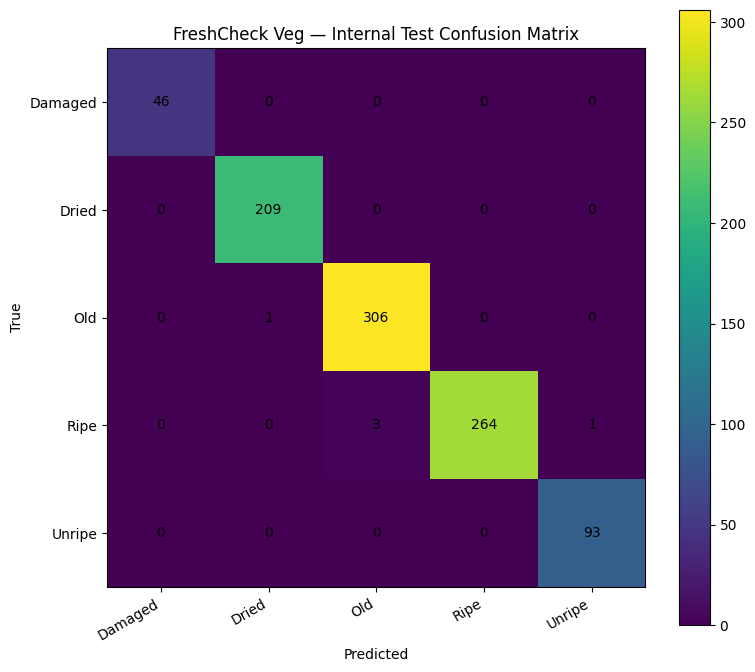

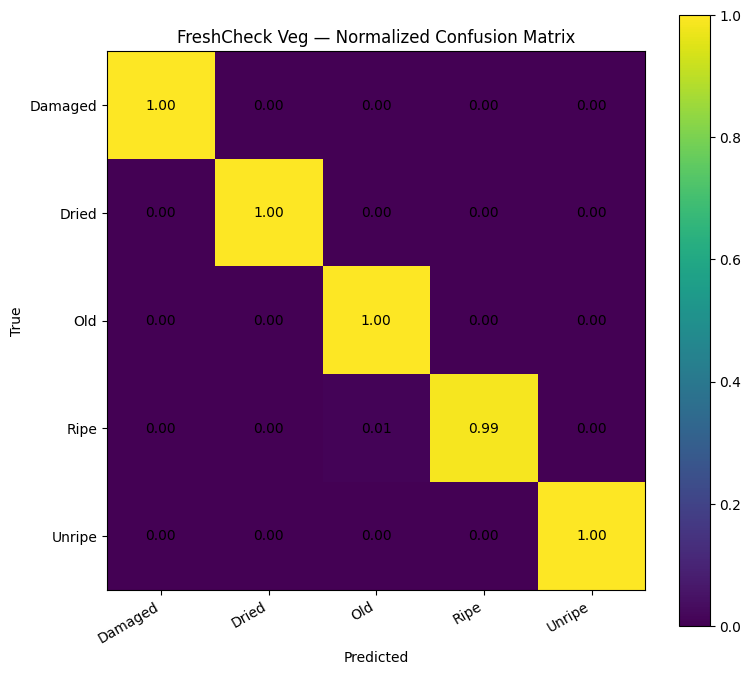

In [21]:

cm = confusion_matrix(
    test_result["y_true"],
    test_result["y_pred"],
    labels=list(range(5)),
)

fig = plt.figure(figsize=(8, 7))
plt.imshow(cm)
plt.colorbar()

plt.xticks(range(5), [LABEL_NAMES[i] for i in range(5)], rotation=30, ha="right")
plt.yticks(range(5), [LABEL_NAMES[i] for i in range(5)])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("FreshCheck Veg — Internal Test Confusion Matrix")

for i in range(5):
    for j in range(5):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.savefig(ASSET_DIR / "test_confusion_matrix.png", dpi=170, bbox_inches="tight")
plt.show()

cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig = plt.figure(figsize=(8, 7))
plt.imshow(cm_norm, vmin=0, vmax=1)
plt.colorbar()

plt.xticks(range(5), [LABEL_NAMES[i] for i in range(5)], rotation=30, ha="right")
plt.yticks(range(5), [LABEL_NAMES[i] for i in range(5)])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("FreshCheck Veg — Normalized Confusion Matrix")

for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.savefig(ASSET_DIR / "test_confusion_matrix_normalized.png", dpi=170, bbox_inches="tight")
plt.show()



## 17. Per-crop evaluation

Because crop and quality are correlated in VegNet, overall metrics are not enough.

This section asks:

> Does the quality classifier behave similarly across Bell Pepper, Chile Pepper, New Mexico Green Chile, and Tomato?

Per-crop Macro-F1 is therefore reported as a diagnostic.


,crop_type,crop_name,n,accuracy,balanced_accuracy,macro_f1_observed_classes
0,0,Bell Pepper,177,0.994350,0.997015,0.996627
1,1,Chile Pepper,193,1.000000,1.000000,1.000000
2,2,New Mexico Green Chile,198,0.979798,0.974872,0.977656
3,3,Tomato,355,1.000000,1.000000,1.000000


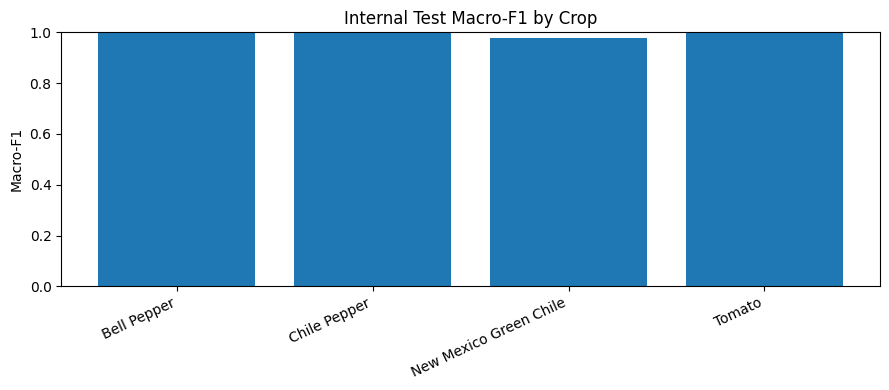

In [22]:

per_crop_rows = []

for crop_id, crop_name in CROP_NAMES.items():
    mask = test_result["crop_type"] == crop_id

    y_true = test_result["y_true"][mask]
    y_pred = test_result["y_pred"][mask]

    if len(y_true) == 0:
        continue

    per_crop_rows.append({
        "crop_type": crop_id,
        "crop_name": crop_name,
        "n": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1_observed_classes": float(
            f1_score(y_true, y_pred, average="macro", zero_division=0)
        ),
    })

per_crop_df = pd.DataFrame(per_crop_rows)
display(per_crop_df)

per_crop_df.to_csv(REPORT_DIR / "test_per_crop_metrics.csv", index=False)

fig = plt.figure(figsize=(9, 4))
plt.bar(per_crop_df["crop_name"], per_crop_df["macro_f1_observed_classes"])
plt.ylim(0, 1)
plt.ylabel("Macro-F1")
plt.title("Internal Test Macro-F1 by Crop")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(ASSET_DIR / "test_macro_f1_by_crop.png", dpi=160, bbox_inches="tight")
plt.show()


## 18. Save per-sample test predictions

In [23]:

test_predictions = test_df[[
    "md5", "label", "label_name", "crop_type", "crop_name"
]].copy()

test_predictions["pred_label"] = test_result["y_pred"]
test_predictions["pred_label_name"] = [
    LABEL_NAMES[int(x)] for x in test_result["y_pred"]
]
test_predictions["correct"] = (
    test_predictions["label"].values == test_predictions["pred_label"].values
)

test_predictions.to_csv(
    REPORT_DIR / "test_predictions.csv",
    index=False,
)

print("[SAVED]", REPORT_DIR / "test_predictions.csv")


[SAVED] /kaggle/working/freshcheck_veg_12pct/reports/test_predictions.csv


## 19. Qualitative predictions — correct and failure cases

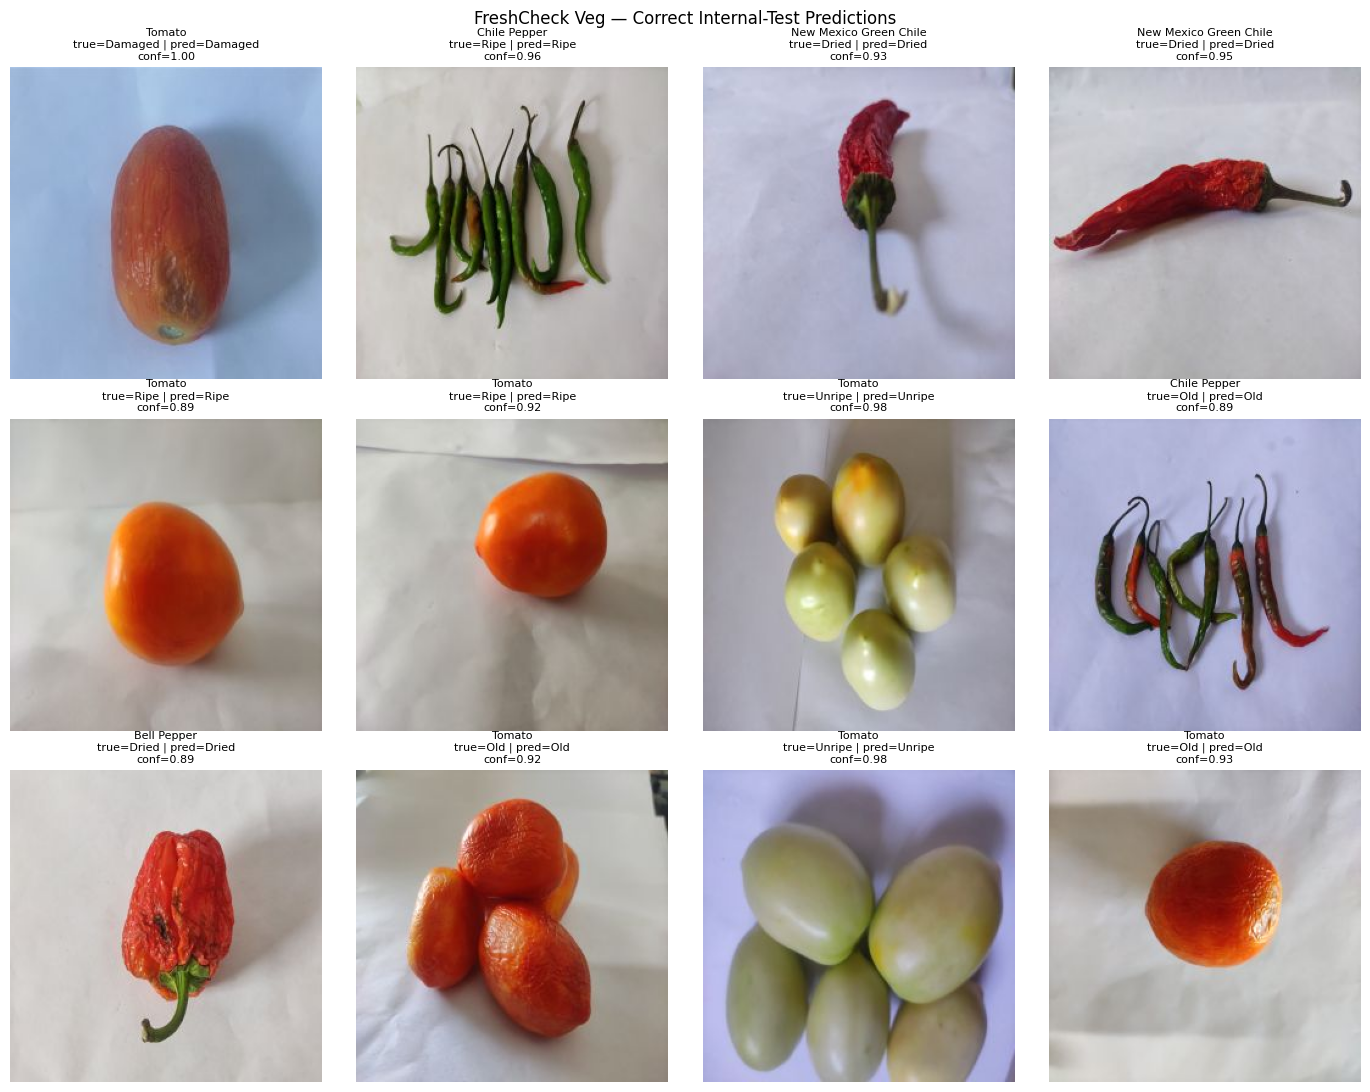

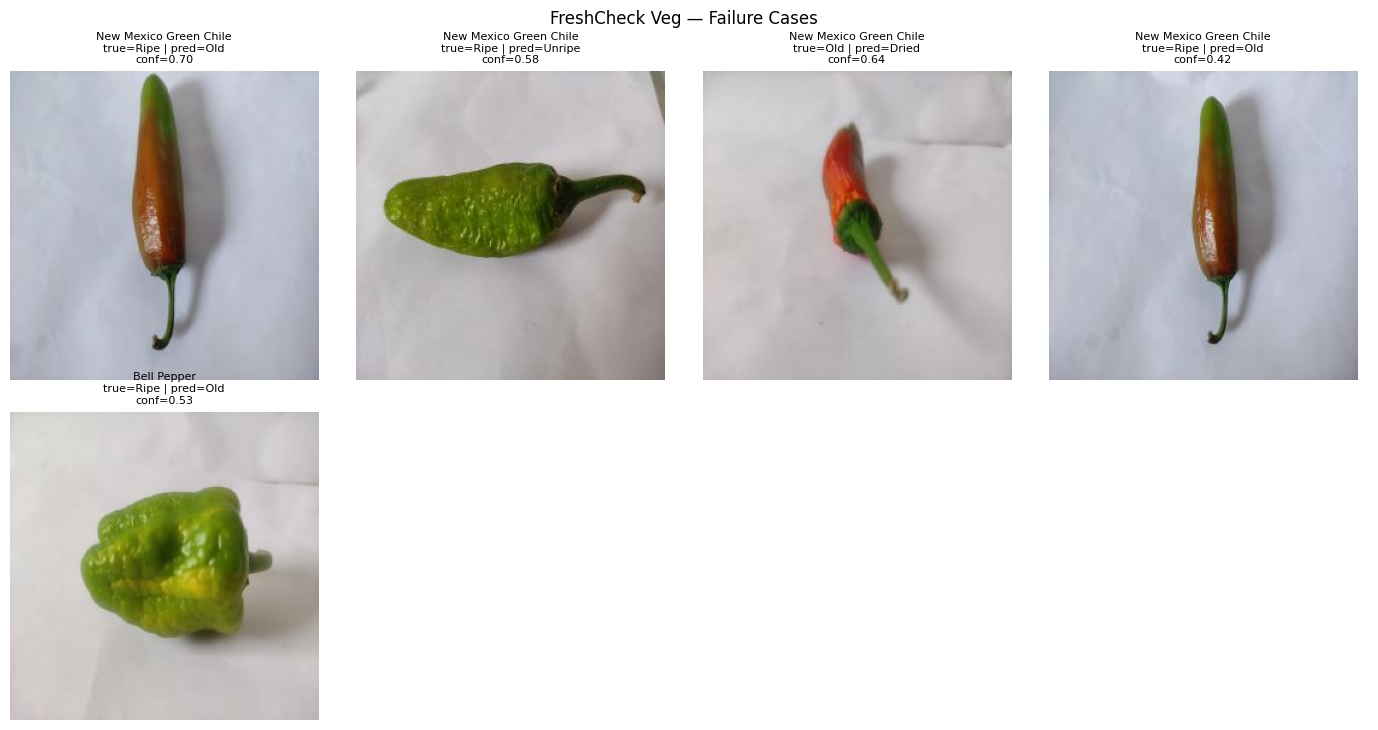

In [24]:

# Re-run test inference with probabilities for qualitative display
all_probs = []

model.eval()
with torch.no_grad():
    for batch in test_loader:
        x = batch["image"].to(DEVICE, non_blocking=True)
        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available(),
        ):
            logits = model(x)
        probs = torch.softmax(logits, dim=1)
        all_probs.append(probs.cpu().numpy())

all_probs = np.concatenate(all_probs, axis=0)
conf = all_probs.max(axis=1)

viz_df = test_df.copy()
viz_df["pred"] = test_result["y_pred"]
viz_df["confidence"] = conf
viz_df["correct"] = viz_df["label"].values == viz_df["pred"].values

def plot_examples(frame, title, filename, n=12):
    if len(frame) == 0:
        print("[VIZ] no examples:", title)
        return

    sample = frame.sample(n=min(n, len(frame)), random_state=SEED)

    rows = math.ceil(len(sample) / 4)
    fig, axes = plt.subplots(rows, 4, figsize=(14, 3.7 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, sample.iterrows()):
        im = decode_image(row["image"])
        ax.imshow(im)

        pred_name = LABEL_NAMES[int(row["pred"])]
        true_name = LABEL_NAMES[int(row["label"])]

        ax.set_title(
            f"{row['crop_name']}\n"
            f"true={true_name} | pred={pred_name}\n"
            f"conf={row['confidence']:.2f}",
            fontsize=8,
        )
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(ASSET_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

plot_examples(
    viz_df[viz_df["correct"]],
    "FreshCheck Veg — Correct Internal-Test Predictions",
    "test_correct_predictions.png",
)

plot_examples(
    viz_df[~viz_df["correct"]],
    "FreshCheck Veg — Failure Cases",
    "test_failure_cases.png",
)



## 20. Inference helper for one image

The function returns:

- predicted quality;
- confidence;
- full class-probability distribution.

**Important:** confidence is model confidence for the visual quality label.  
It is not food-safety certainty.


In [25]:

@torch.no_grad()
def predict_pil(image: Image.Image):
    model.eval()

    x = eval_tfms(image.convert("RGB")).unsqueeze(0).to(DEVICE)

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=torch.cuda.is_available(),
    ):
        logits = model(x)

    probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    pred = int(np.argmax(probs))

    return {
        "pred_label": pred,
        "pred_quality": LABEL_NAMES[pred],
        "confidence": float(probs[pred]),
        "probabilities": {
            LABEL_NAMES[i]: float(probs[i])
            for i in range(5)
        },
    }

sample_row = test_df.iloc[0]
sample_image = decode_image(sample_row["image"])
sample_prediction = predict_pil(sample_image)

print("Ground truth:", sample_row["label_name"])
print(json.dumps(sample_prediction, indent=2))


Ground truth: Dried
{
  "pred_label": 1,
  "pred_quality": "Dried",
  "confidence": 0.91552734375,
  "probabilities": {
    "Damaged": 0.039947509765625,
    "Dried": 0.91552734375,
    "Old": 0.0167694091796875,
    "Ripe": 0.00473785400390625,
    "Unripe": 0.0229949951171875
  }
}


## 21. Final scientific summary

In [26]:

p, r, f1, support = precision_recall_fscore_support(
    test_result["y_true"],
    test_result["y_pred"],
    labels=list(range(5)),
    zero_division=0,
)

per_class = {
    LABEL_NAMES[i]: {
        "precision": float(p[i]),
        "recall": float(r[i]),
        "f1": float(f1[i]),
        "support": int(support[i]),
    }
    for i in range(5)
}

audit_summary = {
    "mounted_rows": int(len(df)),
    "readable_images": int(len(decode_df)),
    "unreadable_images": int(len(bad_indices)),
    "duplicate_hash_groups": int(len(duplicate_hashes)),
    "conflicting_duplicate_hash_groups": int(len(conflicting_hashes)),
    "rows_after_exact_dedup_and_conflict_removal": int(len(work_df)),
    "split": {
        "train": int(len(train_df)),
        "val": int(len(val_df)),
        "test": int(len(test_df)),
    },
    "mounted_label_counts": mounted_counts,
    "mounted_crop_counts": {
        CROP_NAMES[k]: int(v) for k, v in crop_counts.items()
    },
}

final_metrics = {
    "accuracy": float(test_result["accuracy"]),
    "balanced_accuracy": float(test_result["balanced_accuracy"]),
    "macro_f1": float(test_result["macro_f1"]),
    "per_class": per_class,
    "per_crop": per_crop_df.to_dict(orient="records"),
}

summary = {
    "project": "FreshCheck Veg",
    "portfolio_progress": "12%",
    "validated_task": "5-class visual vegetable quality classification",
    "model": "EfficientNet-B0",
    "quality_classes": LABEL_NAMES,
    "crop_types": CROP_NAMES,
    "dataset": {
        "mounted_source": str(PARQUET),
        "hf_dataset": "Project-AgML/VegNet_quality_classification",
        "hf_rows_expected": 6150,
        "original_paper_images": 6850,
        "license": "CC BY 4.0",
        "audit": audit_summary,
    },
    "evaluation": {
        "protocol": "internal 70/15/15 split after exact-hash audit; stratified by crop×quality when feasible",
        "selection_metric": "validation macro-F1",
        "test_metrics": final_metrics,
    },
    "naive_majority_baseline": {
        "class": LABEL_NAMES[majority_class],
        "test_accuracy": float(majority_acc),
        "test_macro_f1": float(majority_macro_f1),
    },
    "limitations": [
        "The Hugging Face conversion has 6,150 rows, while the original paper describes 6,850 images.",
        "The missing 700 images are reflected in the Unripe class, especially Tomato.",
        "Crop type and quality label are statistically associated in the dataset.",
        "The current test split is internal, not external validation.",
        "Images come from the same source dataset and acquisition process.",
        "The model is validated only for the four VegNet crop categories represented here.",
        "Visual quality classification is not food-safety or shelf-life estimation.",
    ],
}

(REPORT_DIR / "dataset_audit.json").write_text(
    json.dumps(audit_summary, indent=2)
)

(REPORT_DIR / "final_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print(json.dumps(summary, indent=2))


{
  "project": "FreshCheck Veg",
  "portfolio_progress": "12%",
  "validated_task": "5-class visual vegetable quality classification",
  "model": "EfficientNet-B0",
  "quality_classes": {
    "0": "Damaged",
    "1": "Dried",
    "2": "Old",
    "3": "Ripe",
    "4": "Unripe"
  },
  "crop_types": {
    "0": "Bell Pepper",
    "1": "Chile Pepper",
    "2": "New Mexico Green Chile",
    "3": "Tomato"
  },
  "dataset": {
    "mounted_source": "/kaggle/input/datasets/loliwibu/vegnet/data/train-00000-of-00001.parquet",
    "hf_dataset": "Project-AgML/VegNet_quality_classification",
    "hf_rows_expected": 6150,
    "original_paper_images": 6850,
    "license": "CC BY 4.0",
    "audit": {
      "mounted_rows": 6150,
      "readable_images": 6150,
      "unreadable_images": 0,
      "duplicate_hash_groups": 0,
      "conflicting_duplicate_hash_groups": 0,
      "rows_after_exact_dedup_and_conflict_removal": 6150,
      "split": {
        "train": 4305,
        "val": 922,
        "test": 923



## 22. Quality gate

The notebook does not force a predetermined accuracy target.

Interpretation is based on:

- Macro-F1;
- balanced accuracy;
- weakest-class recall/F1;
- per-crop behavior;
- confusion matrix;
- failure-case inspection.

A high aggregate accuracy is **not** considered sufficient if the model fails badly on minority classes such as `Damaged` or `Unripe`.


In [27]:

macro_f1 = test_result["macro_f1"]
min_class_f1 = min(v["f1"] for v in per_class.values())
bal_acc = test_result["balanced_accuracy"]

if macro_f1 >= 0.90 and min_class_f1 >= 0.80:
    grade = "VERY STRONG"
elif macro_f1 >= 0.80 and min_class_f1 >= 0.65:
    grade = "STRONG"
elif macro_f1 >= 0.70:
    grade = "USABLE MVP"
else:
    grade = "BASELINE / NEEDS IMPROVEMENT"

print("[QUALITY GATE]", grade)
print(f"[TEST] Accuracy          : {test_result['accuracy']:.4f}")
print(f"[TEST] Balanced Accuracy : {bal_acc:.4f}")
print(f"[TEST] Macro-F1          : {macro_f1:.4f}")
print(f"[TEST] Weakest class F1  : {min_class_f1:.4f}")


[QUALITY GATE] VERY STRONG
[TEST] Accuracy          : 0.9946
[TEST] Balanced Accuracy : 0.9964
[TEST] Macro-F1          : 0.9957
[TEST] Weakest class F1  : 0.9925


## 23. Package outputs for Kaggle Save Version

In [28]:

# Save label/crop mappings separately for later app inference.
mapping = {
    "label_names": LABEL_NAMES,
    "crop_names": CROP_NAMES,
    "img_size": IMG_SIZE,
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225],
    },
}

(REPORT_DIR / "inference_config.json").write_text(
    json.dumps(mapping, indent=2)
)

zip_path = shutil.make_archive(
    "/kaggle/working/freshcheck_veg_12pct_FINAL",
    "zip",
    root_dir=str(WORK),
)

print("\n=== FRESHCHECK VEG 12% DONE ===", flush=True)
print("[DONE] best model:", best_path, flush=True)
print("[DONE] test accuracy:", test_result["accuracy"], flush=True)
print("[DONE] test balanced accuracy:", test_result["balanced_accuracy"], flush=True)
print("[DONE] test macro-F1:", test_result["macro_f1"], flush=True)
print("[DONE] ZIP:", zip_path, flush=True)



=== FRESHCHECK VEG 12% DONE ===
[DONE] best model: /kaggle/working/freshcheck_veg_12pct/models/freshcheck_effnet_b0_best.pt
[DONE] test accuracy: 0.9945828819068255
[DONE] test balanced accuracy: 0.9963634595750888
[DONE] test macro-F1: 0.9956506936172513
[DONE] ZIP: /kaggle/working/freshcheck_veg_12pct_FINAL.zip



# Save Version Checklist

Before clicking **Save Version**:

- [ ] heartbeat visible;
- [ ] Parquet loads successfully;
- [ ] 6,150 mounted rows confirmed or differences documented;
- [ ] label mapping verified;
- [ ] crop mapping verified;
- [ ] crop × quality crosstab reviewed;
- [ ] image decode audit completed;
- [ ] visual dataset examples inspected;
- [ ] exact duplicate audit completed;
- [ ] split hash leakage = 0;
- [ ] train/validation/test split tables inspected;
- [ ] Stage 1 completed;
- [ ] Stage 2 completed;
- [ ] best checkpoint exists;
- [ ] internal held-out test metrics printed;
- [ ] confusion matrix inspected;
- [ ] per-crop metrics inspected;
- [ ] failure cases inspected;
- [ ] final summary JSON exists;
- [ ] final ZIP exists.

Expected output:

```text
/kaggle/working/freshcheck_veg_12pct_FINAL.zip
```

---

# Correct Public Claim

> **FreshCheck Veg is an EfficientNet-B0 MVP for five-class visual quality classification of four vegetable categories represented in the VegNet dataset: Bell Pepper, Chile Pepper, New Mexico Green Chile, and Tomato.**

The five quality classes are:

```text
Damaged
Dried
Old
Ripe
Unripe
```

Do not describe the current model as:

- universal fruit freshness detection;
- food safety detection;
- shelf-life prediction;
- chemical freshness analysis;
- disease diagnosis;
- quality grading for arbitrary produce.

---

# Product Lesson

The key lesson for this milestone is **Grounding**:

> The product definition must follow the dataset that actually exists, not the project title we originally imagined.

That is why the original `FreshCheck Fruit` concept was corrected to **FreshCheck Veg** after inspecting VegNet.
